# CareShield AI — Privacy-Preserving Healthcare Readmission Prediction
## 1. Environment Setup & Data Ingestion

In [1]:
import warnings
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 60)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 100

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print("Core environment ready.")

Core environment ready.


In [2]:
df_structured = pd.read_csv('diabetic_data.csv')
df_text = pd.read_csv('mtsamples.csv')

print(f"Structured dataset shape: {df_structured.shape}")
print(f"Text dataset shape:       {df_text.shape}\n")

print("Structured columns:")
print(df_structured.columns.tolist())

print("\nText columns:")
print(df_text.columns.tolist())

Structured dataset shape: (101766, 50)
Text dataset shape:       (4999, 6)

Structured columns:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

Text columns:
['Unnamed: 0', 'description', 'medical_specialty', 'sample_name', 'tran

In [3]:
print("--- Structured Dataset Preview ---")
display(df_structured.head(5))

print("\n--- Text Dataset Preview ---")
display(df_text.head(5))

--- Structured Dataset Preview ---


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO



--- Text Dataset Preview ---


,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."


In [4]:
print("--- Structured Dataset Info ---")
df_structured.info()

print("\n--- Text Dataset Info ---")
df_text.info()

print("\n--- Structured Numerical Summary ---")
display(df_structured.describe().T)

--- Structured Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14 

,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.024006e+00,1.445403e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.715642e+00,5.280166e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.754437e+00,4.064081e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.395987e+00,2.985108e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.309564e+01,1.967436e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.339730e+00,1.705807e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602184e+01,8.127566e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.693572e-01,1.267265e+00,0.0,0.0,0.0,0.000000e+00,42.0


## Deep Data Quality Audit

In [5]:
# Check exact duplicates and repeated patient visits
print(f"Exact duplicate rows:    {df_structured.duplicated().sum()}")
print(f"Unique encounters:       {df_structured['encounter_id'].nunique()} / {len(df_structured)}")
print(f"Unique patients:         {df_structured['patient_nbr'].nunique()} / {len(df_structured)}")
print(f"Repeated patient visits: {len(df_structured) - df_structured['patient_nbr'].nunique()}")

Exact duplicate rows:    0
Unique encounters:       101766 / 101766
Unique patients:         71518 / 101766
Repeated patient visits: 30248


In [6]:
# Detect explicit NaNs and hidden missing symbols
missing_rows = []
for col in df_structured.columns:
    nan_cnt = df_structured[col].isna().sum()
    if pd.api.types.is_string_dtype(df_structured[col]) or df_structured[col].dtype == 'object':
        hidden_cnt = df_structured[col].isin(['?', 'Unknown/Invalid', '']).sum()
    else:
        hidden_cnt = 0
        
    total_missing = nan_cnt + hidden_cnt
    if total_missing > 0:
        missing_rows.append({
            'column': col,
            'nan_pct': round(nan_cnt / len(df_structured) * 100, 2),
            'hidden_pct': round(hidden_cnt / len(df_structured) * 100, 2),
            'total_missing_pct': round(total_missing / len(df_structured) * 100, 2)
        })

missing_report = pd.DataFrame(missing_rows).sort_values(
    by='total_missing_pct', ascending=False
).reset_index(drop=True)
display(missing_report)

,column,nan_pct,hidden_pct,total_missing_pct
0,weight,0.00,96.86,96.86
1,max_glu_serum,94.75,0.00,94.75
2,A1Cresult,83.28,0.00,83.28
3,medical_specialty,0.00,49.08,49.08
4,payer_code,0.00,39.56,39.56
5,race,0.00,2.23,2.23
6,diag_3,0.00,1.40,1.40
7,diag_2,0.00,0.35,0.35
8,diag_1,0.00,0.02,0.02
9,gender,0.00,0.00,0.00


In [7]:
# Identify columns dominated by a single value (>= 95%)
variance_rows = []
for col in df_structured.columns:
    vc = df_structured[col].value_counts(dropna=False)
    top_pct = round(vc.iloc[0] / len(df_structured) * 100, 2)
    if top_pct >= 95.0:
        variance_rows.append({
            'column': col,
            'nunique': df_structured[col].nunique(dropna=False),
            'top_value': vc.index[0],
            'top_value_pct': top_pct
        })

variance_report = pd.DataFrame(variance_rows).sort_values(
    by='top_value_pct', ascending=False
).reset_index(drop=True)
display(variance_report)

,column,nunique,top_value,top_value_pct
0,acetohexamide,2,No,100.00
1,glimepiride-pioglitazone,2,No,100.00
2,troglitazone,2,No,100.00
3,citoglipton,1,No,100.00
4,metformin-pioglitazone,2,No,100.00
5,examide,1,No,100.00
6,metformin-rosiglitazone,2,No,100.00
7,glipizide-metformin,2,No,99.99
8,tolbutamide,2,No,99.98
9,tolazamide,3,No,99.96


In [8]:
# Inspect raw target classes
print("--- Raw Target Distribution ---")
print(df_structured['readmitted'].value_counts(dropna=False))
print("\nTarget Percentage (%):")
print(df_structured['readmitted'].value_counts(normalize=True).mul(100).round(2))

# Check invalid gender entries and deceased/hospice discharge codes
dead_codes = [11, 13, 14, 19, 20, 21]
print(f"\nInvalid gender rows:   {(df_structured['gender'] == 'Unknown/Invalid').sum()}")
print(f"Deceased/Hospice rows: {df_structured['discharge_disposition_id'].isin(dead_codes).sum()}")

--- Raw Target Distribution ---
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Target Percentage (%):
readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64

Invalid gender rows:   3
Deceased/Hospice rows: 2423


In [9]:
# Audit missing values and unique counts in text dataset
text_audit = pd.DataFrame({
    'missing_count': df_text.isna().sum(),
    'missing_pct': (df_text.isna().mean() * 100).round(2),
    'nunique': df_text.nunique()
})
display(text_audit)

# Check duplicate texts and word length distribution
word_counts = df_text['transcription'].dropna().apply(lambda x: len(str(x).split()))
print(f"\nDuplicate transcriptions: {df_text['transcription'].dropna().duplicated().sum()}")
print("\nTranscription word count stats:")
print(word_counts.describe().round(1))

,missing_count,missing_pct,nunique
Unnamed: 0,0,0.00,4999
description,0,0.00,2348
medical_specialty,0,0.00,40
sample_name,0,0.00,2377
transcription,33,0.66,2357
keywords,1068,21.36,3849



Duplicate transcriptions: 2609

Transcription word count stats:
count    4966.0
mean      465.4
std       316.4
min         1.0
25%       241.0
50%       398.0
75%       615.0
max      3029.0
Name: transcription, dtype: float64


## Visual EDA & Statistical Feature Importance

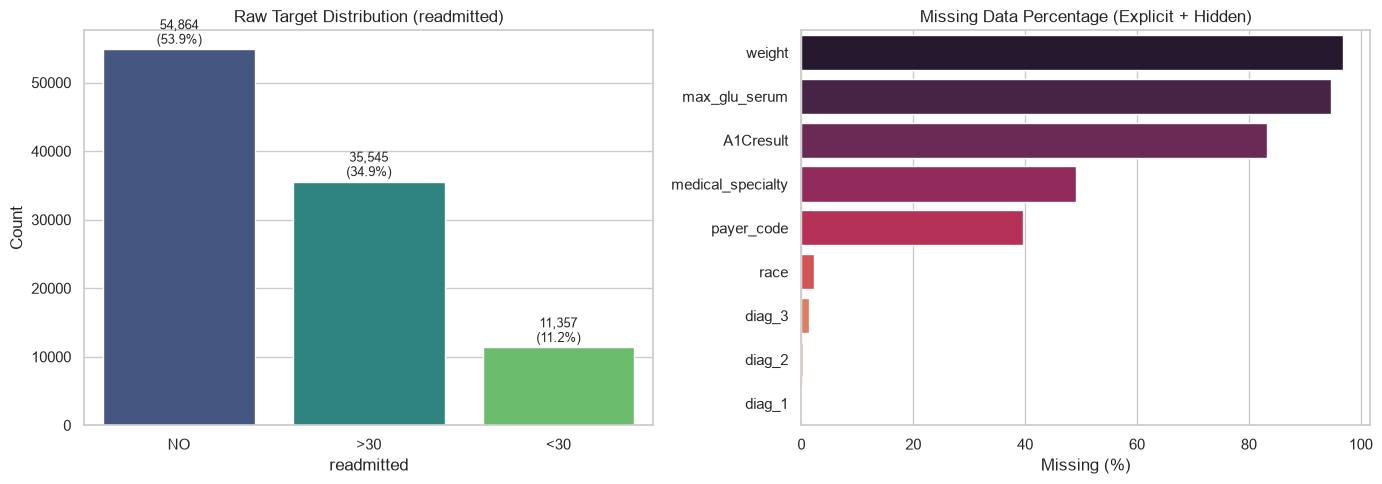

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Target distribution
target_counts = df_structured['readmitted'].value_counts()
sns.barplot(x=target_counts.index, y=target_counts.values, ax=axes[0], palette='viridis')
axes[0].set_title('Raw Target Distribution (readmitted)')
axes[0].set_ylabel('Count')
for i, v in enumerate(target_counts.values):
    pct = v / len(df_structured) * 100
    axes[0].text(i, v + 800, f'{v:,}\n({pct:.1f}%)', ha='center', fontsize=9)

# Plot 2: Missing values breakdown
sns.barplot(
    data=missing_report[missing_report['total_missing_pct'] > 0],
    x='total_missing_pct',
    y='column',
    ax=axes[1],
    palette='rocket'
)
axes[1].set_title('Missing Data Percentage (Explicit + Hidden)')
axes[1].set_xlabel('Missing (%)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

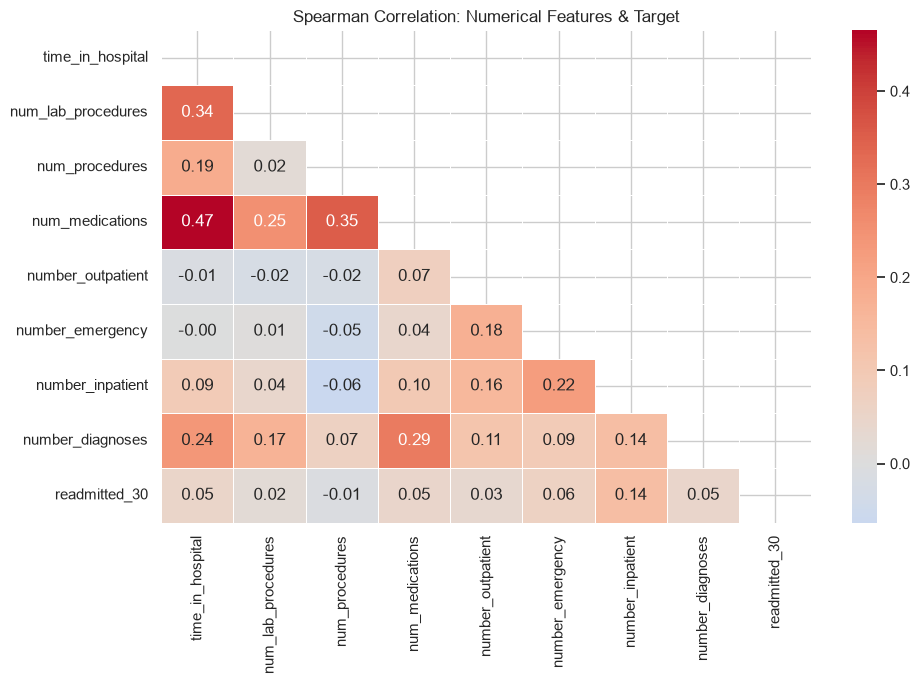

In [11]:
num_cols = [
    'time_in_hospital', 'num_lab_procedures', 'num_procedures',
    'num_medications', 'number_outpatient', 'number_emergency',
    'number_inpatient', 'number_diagnoses'
]

# Temporary EDA dataframe with binary target
df_eda = df_structured.copy()
df_eda['readmitted_30'] = (df_eda['readmitted'] == '<30').astype(int)

corr_matrix = df_eda[num_cols + ['readmitted_30']].corr(method='spearman')

plt.figure(figsize=(10, 7))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)
plt.title('Spearman Correlation: Numerical Features & Target')
plt.tight_layout()
plt.show()

,feature,skewness,q3,max,iqr_outlier_pct
0,number_emergency,22.86,0.0,76,11.19
1,number_outpatient,8.83,0.0,42,16.45
2,number_inpatient,3.61,1.0,21,6.93
3,num_medications,1.33,20.0,81,2.51
4,num_procedures,1.32,2.0,6,4.87
5,time_in_hospital,1.13,6.0,14,2.21
6,num_lab_procedures,-0.24,57.0,132,0.14
7,number_diagnoses,-0.88,9.0,16,0.06


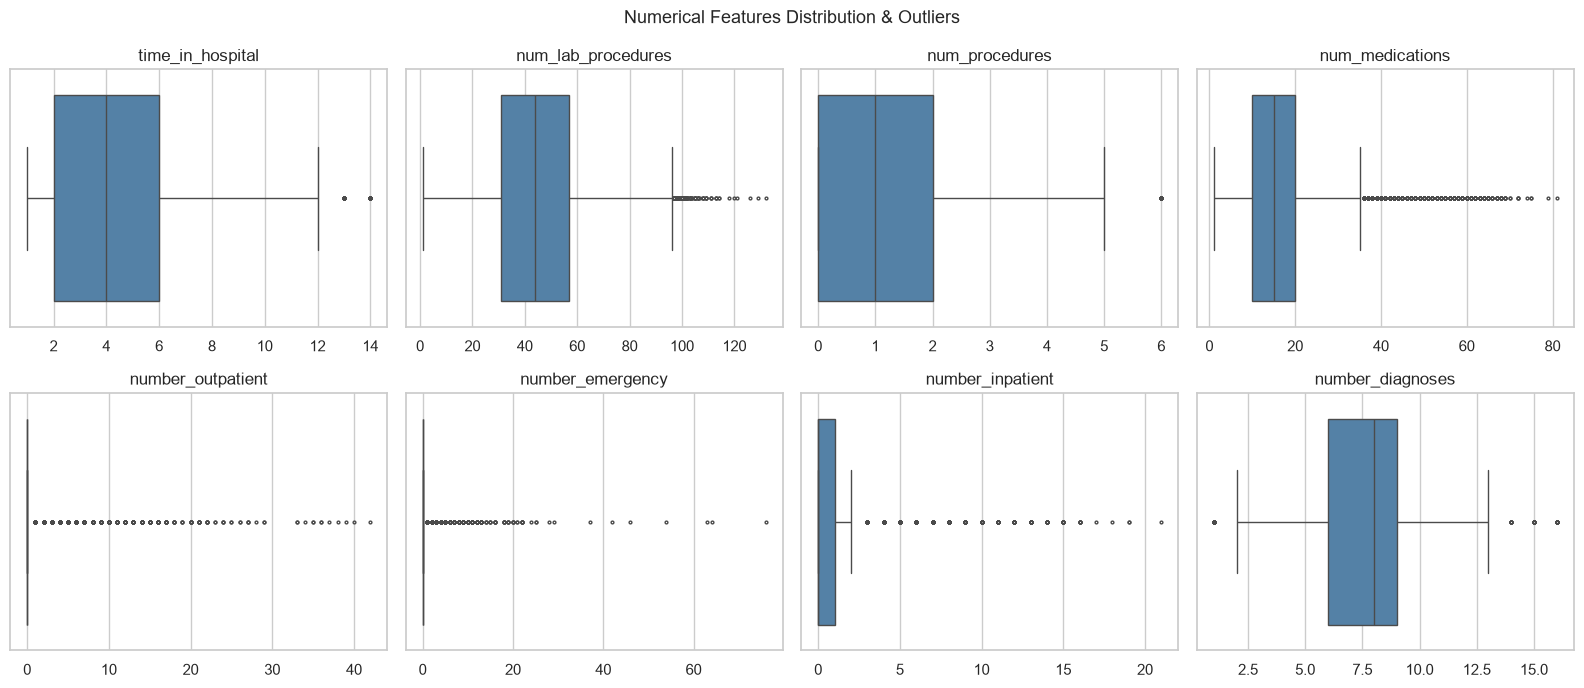

In [12]:
# Calculate skewness and IQR outlier percentage
outlier_rows = []
for col in num_cols:
    q1 = df_eda[col].quantile(0.25)
    q3 = df_eda[col].quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr
    outlier_pct = (df_eda[col] > upper_bound).mean() * 100
    outlier_rows.append({
        'feature': col,
        'skewness': round(df_eda[col].skew(), 2),
        'q3': q3,
        'max': df_eda[col].max(),
        'iqr_outlier_pct': round(outlier_pct, 2)
    })

display(pd.DataFrame(outlier_rows).sort_values(by='skewness', ascending=False).reset_index(drop=True))

# Boxplots for numerical features
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(x=df_eda[col], ax=ax, color='steelblue', fliersize=2)
    ax.set_title(col)
    ax.set_xlabel('')

plt.suptitle('Numerical Features Distribution & Outliers', fontsize=13)
plt.tight_layout()
plt.show()

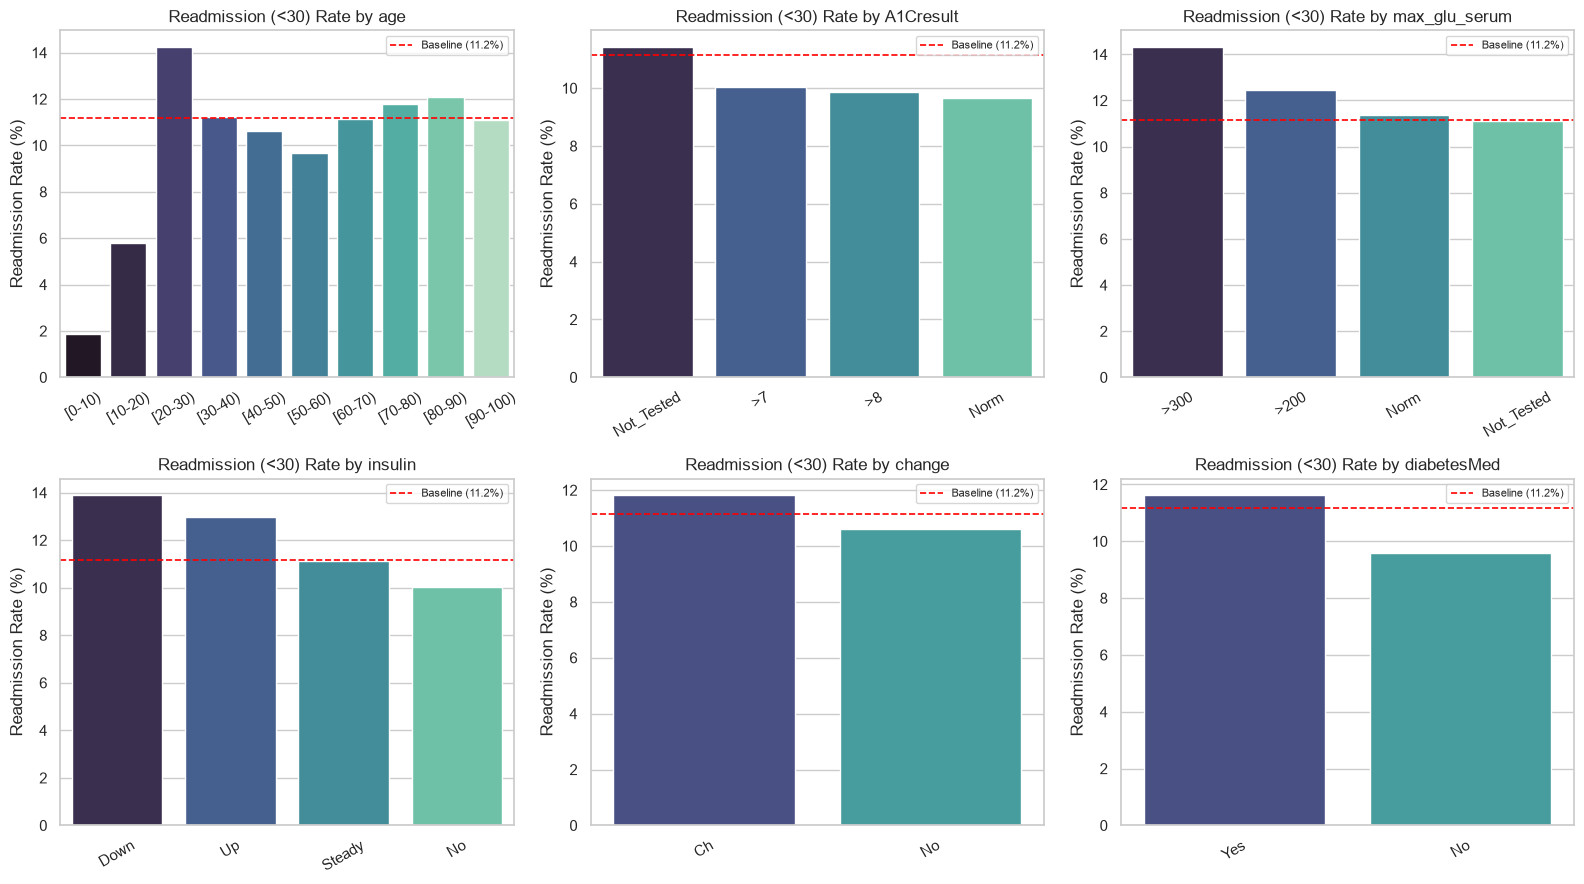

In [13]:
# Prepare temporary copy for clean plotting
df_plot = df_eda.copy()
df_plot['A1Cresult'] = df_plot['A1Cresult'].fillna('Not_Tested')
df_plot['max_glu_serum'] = df_plot['max_glu_serum'].fillna('Not_Tested')

cat_check = ['age', 'A1Cresult', 'max_glu_serum', 'insulin', 'change', 'diabetesMed']
baseline_rate = df_plot['readmitted_30'].mean() * 100

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), cat_check):
    rates = df_plot.groupby(col)['readmitted_30'].mean().mul(100)
    if col != 'age':
        rates = rates.sort_values(ascending=False)
    sns.barplot(x=rates.index, y=rates.values, ax=ax, palette='mako')
    ax.axhline(baseline_rate, color='red', linestyle='--', linewidth=1.2, label=f'Baseline ({baseline_rate:.1f}%)')
    ax.set_title(f'Readmission (<30) Rate by {col}')
    ax.set_ylabel('Readmission Rate (%)')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [14]:
from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.feature_selection import mutual_info_classif

# Prepare categorical and coded ID columns
exclude_cols = num_cols + ['encounter_id', 'patient_nbr', 'readmitted', 'readmitted_30']
cat_cols = [c for c in df_eda.columns if c not in exclude_cols]

chi2_results = []
for col in cat_cols:
    series = df_eda[col].fillna('Missing').astype(str)
    ct = pd.crosstab(series, df_eda['readmitted_30'])
    if ct.shape[0] < 2:
        chi2_results.append({'feature': col, 'p_value': 1.0, 'cramers_v': 0.0, 'significant': False})
        continue
    chi2, p_val, _, _ = chi2_contingency(ct)
    n = ct.sum().sum()
    min_dim = min(ct.shape) - 1
    cramers_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else 0.0
    chi2_results.append({
        'feature': col,
        'p_value': round(p_val, 5),
        'cramers_v': round(cramers_v, 4),
        'significant': p_val < 0.05
    })

cat_importance = pd.DataFrame(chi2_results).sort_values(
    by='cramers_v', ascending=False
).reset_index(drop=True)

print("Top 15 Categorical/ID Features (Cramér's V):")
display(cat_importance.head(15))
print("Bottom 15 Categorical/ID Features (Weakest):")
display(cat_importance.tail(15))

Top 15 Categorical/ID Features (Cramér's V):


,feature,p_value,cramers_v,significant
0,diag_1,0.00000,0.1323,True
1,discharge_disposition_id,0.00000,0.1247,True
2,diag_3,0.00000,0.1238,True
3,diag_2,0.00000,0.1163,True
4,medical_specialty,0.00000,0.0583,True
5,insulin,0.00000,0.0433,True
6,age,0.00000,0.0339,True
7,payer_code,0.00000,0.0310,True
8,diabetesMed,0.00000,0.0271,True
9,metformin,0.00000,0.0240,True


Bottom 15 Categorical/ID Features (Weakest):


,feature,p_value,cramers_v,significant
24,acarbose,0.21903,0.0066,False
25,chlorpropamide,0.43332,0.0052,False
26,nateglinide,0.70284,0.0037,False
27,gender,0.53868,0.0035,False
28,glyburide-metformin,0.75558,0.0034,False
29,tolazamide,0.76551,0.0023,False
30,tolbutamide,0.47986,0.0022,False
31,acetohexamide,1.00000,0.0000,False
32,citoglipton,1.00000,0.0000,False
33,troglitazone,1.00000,0.0000,False


,feature,median_no_risk,median_risk,p_value,mutual_info
0,number_inpatient,0.0,0.0,0.00000,0.0112
1,number_diagnoses,8.0,9.0,0.00000,0.0083
2,time_in_hospital,4.0,4.0,0.00000,0.0039
3,number_emergency,0.0,0.0,0.00000,0.0039
4,number_outpatient,0.0,0.0,0.00000,0.0017
5,num_medications,15.0,16.0,0.00000,0.0015
6,num_procedures,1.0,1.0,0.05115,0.0014
7,num_lab_procedures,44.0,45.0,0.00000,0.0000


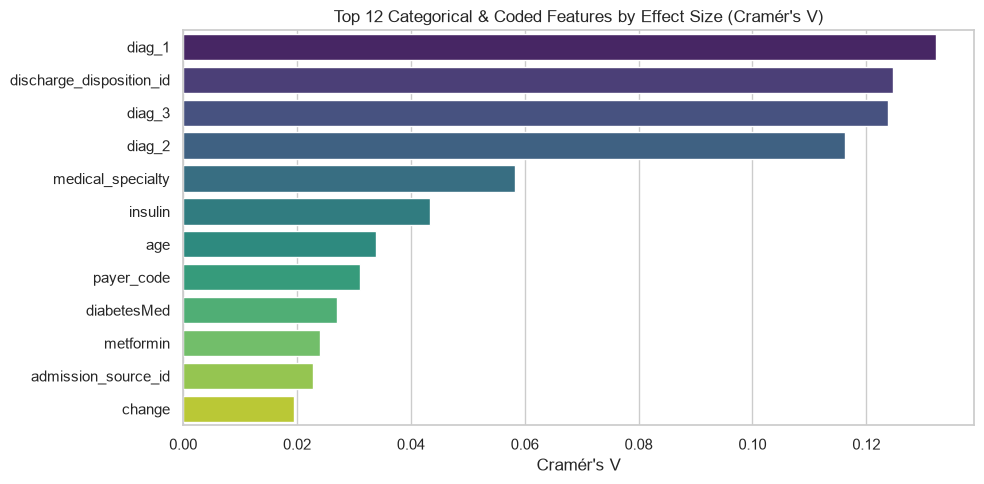

In [15]:
# Statistical test and Mutual Information for numerical features
num_results = []
mi_scores = mutual_info_classif(df_eda[num_cols], df_eda['readmitted_30'], random_state=SEED)

for col, mi in zip(num_cols, mi_scores):
    g0 = df_eda.loc[df_eda['readmitted_30'] == 0, col]
    g1 = df_eda.loc[df_eda['readmitted_30'] == 1, col]
    _, p_val = mannwhitneyu(g0, g1, alternative='two-sided')
    num_results.append({
        'feature': col,
        'median_no_risk': g0.median(),
        'median_risk': g1.median(),
        'p_value': round(p_val, 5),
        'mutual_info': round(mi, 4)
    })

num_importance = pd.DataFrame(num_results).sort_values(
    by='mutual_info', ascending=False
).reset_index(drop=True)
display(num_importance)

# Visualize top 12 categorical features by Cramér's V
plt.figure(figsize=(10, 5))
sns.barplot(data=cat_importance.head(12), x='cramers_v', y='feature', palette='viridis')
plt.title("Top 12 Categorical & Coded Features by Effect Size (Cramér's V)")
plt.xlabel("Cramér's V")
plt.ylabel('')
plt.tight_layout()
plt.show()

## Data Cleaning & Clinical Feature Engineering

In [16]:
df_clean = df_structured.copy()

# Keep only the first chronological visit per patient
df_clean = df_clean.sort_values('encounter_id').drop_duplicates(
    subset=['patient_nbr'], keep='first'
)

print(f"After deduplication: {df_clean.shape}")

After deduplication: (71518, 50)


In [17]:
# Remove deceased/hospice discharges and invalid gender entries
dead_codes = [11, 13, 14, 19, 20, 21]
df_clean = df_clean[~df_clean['discharge_disposition_id'].isin(dead_codes)]
df_clean = df_clean[df_clean['gender'] != 'Unknown/Invalid']

# Drop high-missing and administrative columns
df_clean = df_clean.drop(columns=['weight', 'payer_code'])

print(f"After clinical filtering & drops: {df_clean.shape}")

After clinical filtering & drops: (69970, 48)


In [18]:
# Binarize target: <30 days = 1 (High Risk), otherwise = 0
df_clean['readmitted'] = (df_clean['readmitted'] == '<30').astype(int)
df_clean = df_clean.reset_index(drop=True)

print(f"Clean shape: {df_clean.shape}")
print("\nBinary target distribution (%):")
print(df_clean['readmitted'].value_counts(normalize=True).mul(100).round(2))

Clean shape: (69970, 48)

Binary target distribution (%):
readmitted
0    91.03
1     8.97
Name: proportion, dtype: float64


In [19]:
# Handle missing values in race and lab results
df_clean['race'] = df_clean['race'].replace('?', 'Unknown').fillna('Unknown')
df_clean['A1Cresult'] = df_clean['A1Cresult'].fillna('Not_Tested')
df_clean['max_glu_serum'] = df_clean['max_glu_serum'].fillna('Not_Tested')

# Map ordinal age brackets to numeric midpoints
age_map = {
    '[0-10)': 5, '[10-20)': 15, '[20-30)': 25, '[30-40)': 35, '[40-50)': 45,
    '[50-60)': 55, '[60-70)': 65, '[70-80)': 75, '[80-90)': 85, '[90-100)': 95
}
df_clean['age_numeric'] = df_clean['age'].map(age_map)
df_clean = df_clean.drop(columns=['age'])

print("Remaining missing values (top 5):")
print(df_clean.isna().sum().sort_values(ascending=False).head(5))

Remaining missing values (top 5):
encounter_id         0
patient_nbr          0
race                 0
gender               0
admission_type_id    0
dtype: int64


In [20]:
def map_icd9_category(code):
    if pd.isna(code) or str(code).strip() == '?':
        return 'Missing'
    code_str = str(code).strip()
    if code_str.startswith(('V', 'E')):
        return 'Other'
    try:
        num = float(code_str)
    except ValueError:
        return 'Other'
    
    if 250 <= num < 251:
        return 'Diabetes'
    elif (390 <= num <= 459) or num == 785:
        return 'Circulatory'
    elif (460 <= num <= 519) or num == 786:
        return 'Respiratory'
    elif (520 <= num <= 579) or num == 787:
        return 'Digestive'
    elif 800 <= num <= 999:
        return 'Injury'
    elif 710 <= num <= 739:
        return 'Musculoskeletal'
    elif (580 <= num <= 629) or num == 788:
        return 'Genitourinary'
    elif 140 <= num <= 239:
        return 'Neoplasms'
    return 'Other'

for col in ['diag_1', 'diag_2', 'diag_3']:
    df_clean[f'{col}_group'] = df_clean[col].apply(map_icd9_category)

df_clean = df_clean.drop(columns=['diag_1', 'diag_2', 'diag_3'])

print("Primary diagnosis (diag_1_group) distribution:")
print(df_clean['diag_1_group'].value_counts())

Primary diagnosis (diag_1_group) distribution:
diag_1_group
Circulatory        21383
Other              12122
Respiratory         9486
Digestive           6487
Diabetes            5748
Injury              4692
Musculoskeletal     4064
Genitourinary       3440
Neoplasms           2538
Missing               10
Name: count, dtype: int64


In [21]:
med_cols = [
    'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride',
    'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone',
    'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide',
    'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin',
    'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone'
]

# Summarize active medications and dosage changes before dropping rare columns
df_clean['num_active_meds'] = (df_clean[med_cols] != 'No').sum(axis=1)
df_clean['num_med_changes'] = df_clean[med_cols].isin(['Up', 'Down']).sum(axis=1)

# Drop the 16 constant/near-zero variance medication columns
low_var_meds = [
    'acetohexamide', 'glimepiride-pioglitazone', 'troglitazone', 'citoglipton',
    'metformin-pioglitazone', 'examide', 'metformin-rosiglitazone', 'glipizide-metformin',
    'tolbutamide', 'tolazamide', 'miglitol', 'chlorpropamide', 'acarbose',
    'glyburide-metformin', 'nateglinide', 'repaglinide'
]
df_clean = df_clean.drop(columns=low_var_meds)

print(f"Shape after medication engineering: {df_clean.shape}")
print("\nSummary of engineered medication features:")
display(df_clean[['num_active_meds', 'num_med_changes']].describe().round(2))

Shape after medication engineering: (69970, 34)

Summary of engineered medication features:


,num_active_meds,num_med_changes
count,69970.00,69970.00
mean,1.19,0.26
std,0.94,0.48
min,0.00,0.00
25%,1.00,0.00
50%,1.00,0.00
75%,2.00,0.00
max,6.00,4.00


In [22]:
# Overall dataset integrity metrics
print(f"Current shape:       {df_clean.shape}")
print(f"Total explicit NaNs: {df_clean.isna().sum().sum()}")
print(f"Duplicate patients:  {df_clean['patient_nbr'].duplicated().sum()}")

# Column-level summary table
summary_rows = []
for col in df_clean.columns:
    is_text = pd.api.types.is_string_dtype(df_clean[col]) or df_clean[col].dtype == 'object'
    hidden_q = (df_clean[col] == '?').sum() if is_text else 0
    summary_rows.append({
        'column': col,
        'dtype': str(df_clean[col].dtype),
        'nunique': df_clean[col].nunique(),
        'hidden_q_count': hidden_q,
        'top_value': df_clean[col].value_counts().index[0]
    })

display(pd.DataFrame(summary_rows))
display(df_clean.head(3))

Current shape:       (69970, 34)
Total explicit NaNs: 0
Duplicate patients:  0


,column,dtype,nunique,hidden_q_count,top_value
0,encounter_id,int64,69970,0,12522
1,patient_nbr,int64,69970,0,48330783
2,race,str,6,0,Caucasian
3,gender,str,2,0,Female
4,admission_type_id,int64,8,0,1
5,discharge_disposition_id,int64,21,0,1
6,admission_source_id,int64,17,0,7
7,time_in_hospital,int64,14,0,3
8,medical_specialty,str,71,33637,?
9,num_lab_procedures,int64,116,0,1


,encounter_id,patient_nbr,race,gender,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,max_glu_serum,A1Cresult,metformin,glimepiride,glipizide,glyburide,pioglitazone,rosiglitazone,insulin,change,diabetesMed,readmitted,age_numeric,diag_1_group,diag_2_group,diag_3_group,num_active_meds,num_med_changes
0,12522,48330783,Caucasian,Female,2,1,4,13,?,68,2,28,0,0,0,8,Not_Tested,Not_Tested,No,No,Steady,No,No,No,Steady,Ch,Yes,0,85,Circulatory,Circulatory,Other,2,0
1,15738,63555939,Caucasian,Female,3,3,4,12,InternalMedicine,33,3,18,0,0,0,8,Not_Tested,Not_Tested,No,No,No,No,No,Steady,Steady,Ch,Yes,0,95,Circulatory,Neoplasms,Respiratory,2,0
2,16680,42519267,Caucasian,Male,1,1,7,1,?,51,0,8,0,0,0,5,Not_Tested,Not_Tested,No,No,Steady,No,No,No,Steady,Ch,Yes,0,45,Neoplasms,Neoplasms,Diabetes,2,0


In [23]:
# Clean and group rare medical specialties
df_clean['medical_specialty'] = (
    df_clean['medical_specialty'].replace('?', 'Unknown').fillna('Unknown')
)
top_specialties = df_clean['medical_specialty'].value_counts().nlargest(12).index
df_clean['medical_specialty'] = df_clean['medical_specialty'].where(
    df_clean['medical_specialty'].isin(top_specialties), 'Other'
)

# Map coded hospital IDs to clinical categories
def map_discharge(code):
    if code == 1:
        return 'Home'
    elif code in [6, 8]:
        return 'Home_Health'
    elif code in [3, 4, 5]:
        return 'SNF_ICF'
    elif code in [2, 22, 23, 24]:
        return 'Hospital_Rehab_Transfer'
    elif code in [18, 25, 26]:
        return 'Unknown'
    return 'Other'

def map_admission_type(code):
    if code == 1:
        return 'Emergency'
    elif code == 2:
        return 'Urgent'
    elif code == 3:
        return 'Elective'
    elif code in [5, 6, 8]:
        return 'Unknown'
    return 'Other'

def map_admission_source(code):
    if code == 7:
        return 'Emergency_Room'
    elif code in [1, 2, 3]:
        return 'Referral'
    elif code in [4, 5, 6, 10, 22, 25]:
        return 'Transfer'
    elif code in [9, 15, 17, 20, 21]:
        return 'Unknown'
    return 'Other'

df_clean['discharge_group'] = df_clean['discharge_disposition_id'].apply(map_discharge)
df_clean['admission_type_group'] = df_clean['admission_type_id'].apply(map_admission_type)
df_clean['admission_source_group'] = df_clean['admission_source_id'].apply(map_admission_source)

df_clean = df_clean.drop(columns=[
    'discharge_disposition_id', 'admission_type_id', 'admission_source_id'
])

print("Discharge groups distribution:")
print(df_clean['discharge_group'].value_counts())

Discharge groups distribution:
discharge_group
Home                       44315
SNF_ICF                    10238
Home_Health                 8362
Unknown                     3252
Hospital_Rehab_Transfer     3233
Other                        570
Name: count, dtype: int64


In [24]:
# Prior hospital utilization features
df_clean['total_prior_visits'] = (
    df_clean['number_outpatient']
    + df_clean['number_emergency']
    + df_clean['number_inpatient']
)
df_clean['log_total_visits'] = np.log1p(df_clean['total_prior_visits'])
df_clean['inpatient_ratio'] = df_clean['number_inpatient'] / (df_clean['total_prior_visits'] + 1)

# Care intensity during current stay
df_clean['meds_per_day'] = df_clean['num_medications'] / df_clean['time_in_hospital']
df_clean['labs_per_day'] = df_clean['num_lab_procedures'] / df_clean['time_in_hospital']
df_clean['clinical_intensity'] = (
    df_clean['num_lab_procedures'] + df_clean['num_procedures'] + df_clean['num_medications']
) / df_clean['time_in_hospital']

# High-risk binary clinical flags
df_clean['has_prior_inpatient'] = (df_clean['number_inpatient'] > 0).astype(int)
df_clean['has_prior_emergency'] = (df_clean['number_emergency'] > 0).astype(int)

print(f"Final engineered structured shape: {df_clean.shape}")

Final engineered structured shape: (69970, 42)


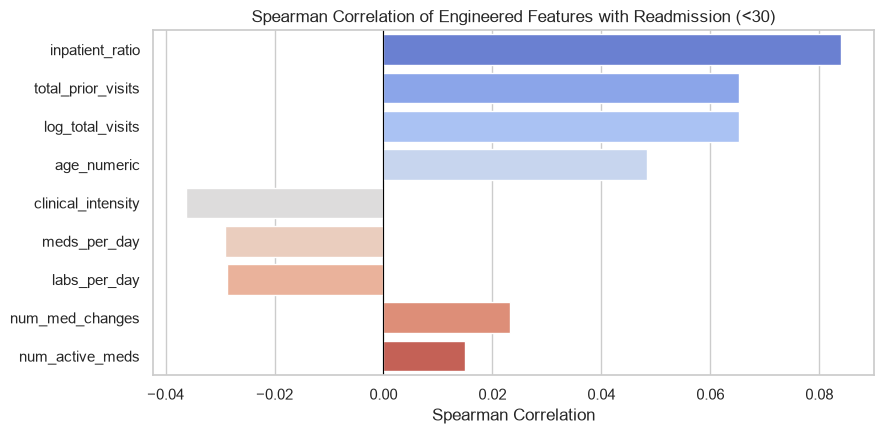


Readmission rate (%) by discharge_group:
discharge_group
Hospital_Rehab_Transfer    18.31
Other                      16.14
SNF_ICF                    13.87
Home_Health                 9.52
Unknown                     9.19
Home                        6.95
Name: readmitted, dtype: float64


In [25]:
engineered_num = [
    'total_prior_visits', 'log_total_visits', 'inpatient_ratio',
    'meds_per_day', 'labs_per_day', 'clinical_intensity',
    'num_active_meds', 'num_med_changes', 'age_numeric'
]

# Spearman correlation of engineered features with target
eng_corr = df_clean[engineered_num + ['readmitted']].corr(method='spearman')['readmitted'].drop('readmitted')
eng_corr = eng_corr.sort_values(key=abs, ascending=False)

plt.figure(figsize=(9, 4.5))
sns.barplot(x=eng_corr.values, y=eng_corr.index, palette='coolwarm')
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Spearman Correlation of Engineered Features with Readmission (<30)')
plt.xlabel('Spearman Correlation')
plt.ylabel('')
plt.tight_layout()
plt.show()

# Verify readmission rate across discharge groups
print("\nReadmission rate (%) by discharge_group:")
print(df_clean.groupby('discharge_group')['readmitted'].mean().mul(100).round(2).sort_values(ascending=False))

## Clinical Text Cleaning & Visual Audit

In [26]:
df_text_clean = df_text.drop(columns=['Unnamed: 0'], errors='ignore').copy()
df_text_clean = df_text_clean.dropna(subset=['transcription'])

for col in ['medical_specialty', 'description', 'transcription', 'keywords']:
    df_text_clean[col] = df_text_clean[col].fillna('').astype(str).str.strip()

# Remove duplicate clinical notes and ultra-short entries
df_text_clean = df_text_clean.drop_duplicates(subset=['transcription']).reset_index(drop=True)
df_text_clean['word_count'] = df_text_clean['transcription'].apply(lambda x: len(x.split()))
df_text_clean = df_text_clean[df_text_clean['word_count'] >= 30].reset_index(drop=True)

print(f"Raw text rows:      {len(df_text)}")
print(f"Clean unique notes: {len(df_text_clean)}")
print(f"Unique specialties: {df_text_clean['medical_specialty'].nunique()}")

Raw text rows:      4999
Clean unique notes: 2324
Unique specialties: 39


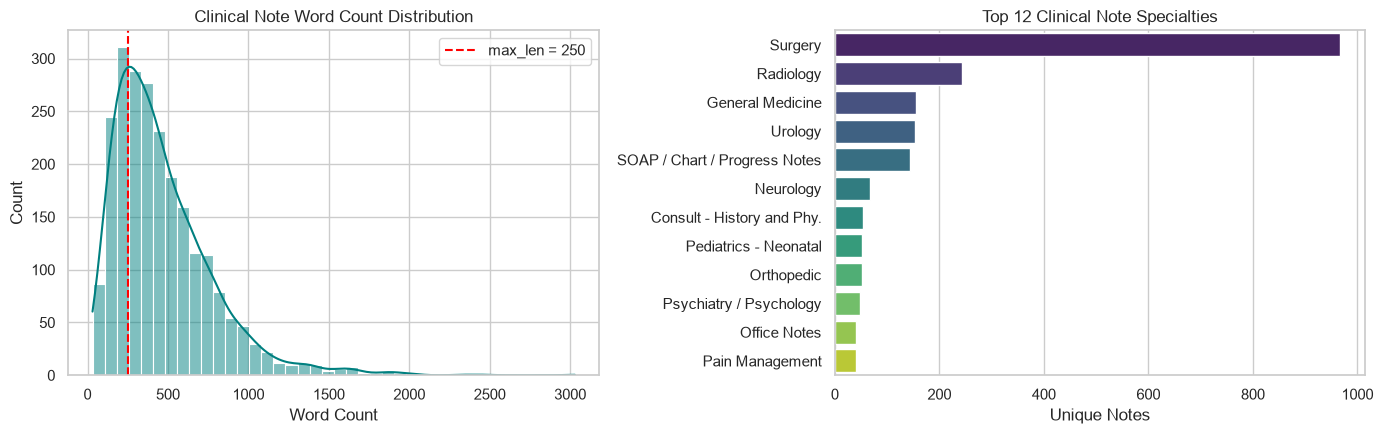

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(df_text_clean['word_count'], bins=40, kde=True, ax=axes[0], color='teal')
axes[0].axvline(250, color='red', linestyle='--', label='max_len = 250')
axes[0].set_title('Clinical Note Word Count Distribution')
axes[0].set_xlabel('Word Count')
axes[0].legend()

top_spec = df_text_clean['medical_specialty'].value_counts().head(12)
sns.barplot(x=top_spec.values, y=top_spec.index, ax=axes[1], palette='viridis')
axes[1].set_title('Top 12 Clinical Note Specialties')
axes[1].set_xlabel('Unique Notes')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

## Privacy-Preserving Pipeline (HIPAA/GDPR) & Stratified Split

In [28]:
import hashlib

df_private = df_clean.copy()
SALT = "CareShield_AI_HIPAA_2026"

# Pseudonymize direct patient identifier with salted SHA-256
df_private['patient_token'] = df_private['patient_nbr'].apply(
    lambda x: hashlib.sha256(f"{SALT}_{x}".encode()).hexdigest()[:16]
)

# Drop raw direct identifiers
df_private = df_private.drop(columns=['encounter_id', 'patient_nbr'])

# HIPAA Safe Harbor: aggregate ages above 89 into a single 90+ bracket
df_private['age_numeric'] = df_private['age_numeric'].clip(upper=90)

print(f"De-identified structured shape: {df_private.shape}")
print("Sample pseudonymized tokens:", df_private['patient_token'].head(3).tolist())
print("Max age after HIPAA generalization:", df_private['age_numeric'].max())

De-identified structured shape: (69970, 41)
Sample pseudonymized tokens: ['7cf43f918cd9a880', '9b4e3572dab0a26c', 'dc04cc0183e73777']
Max age after HIPAA generalization: 90


In [29]:
import re

df_text_private = df_text_clean.copy()

pii_patterns = {
    'DATE': r'\b(?:\d{1,2}[/-]\d{1,2}[/-]\d{2,4}|(?:Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)[a-z]*\s+\d{1,2},?\s+\d{4})\b',
    'DOCTOR': r'\bDr\.\s+[A-Z][a-z]+(?:\s+[A-Z][a-z]+)?\b',
    'PHONE': r'\b(?:\+?1[-.\s]?)?\(?\d{3}\)?[-.\s]\d{3}[-.\s]\d{4}\b',
    'EMAIL': r'\b[\w\.-]+@[\w\.-]+\.\w+\b',
    'ID_NUM': r'\b\d{3}-\d{2}-\d{4}\b'
}

redaction_counts = {k: 0 for k in pii_patterns}

def scrub_pii(text):
    for label, pattern in pii_patterns.items():
        matches = re.findall(pattern, text)
        redaction_counts[label] += len(matches)
        text = re.sub(pattern, f'[{label}]', text)
    return text

df_text_private['transcription'] = df_text_private['transcription'].apply(scrub_pii)

print("PII Redaction Summary across clinical notes:")
for k, v in redaction_counts.items():
    print(f"  {k:<8}: {v}")

PII Redaction Summary across clinical notes:
  DATE    : 1285
  DOCTOR  : 86
  PHONE   : 1
  EMAIL   : 0
  ID_NUM  : 0


In [30]:
from sklearn.model_selection import train_test_split

# Shared stratified split for patients (used by both DL and ML)
train_idx, test_idx = train_test_split(
    df_private.index,
    test_size=0.2,
    stratify=df_private['readmitted'],
    random_state=SEED
)

train_df = df_private.loc[train_idx].copy()
test_df = df_private.loc[test_idx].copy()

# Disjoint split for unique clinical notes (zero text overlap between train and test)
train_notes, test_notes = train_test_split(
    df_text_private,
    test_size=0.2,
    random_state=SEED
)
train_notes = train_notes.reset_index(drop=True)
test_notes = test_notes.reset_index(drop=True)

print(f"Patients -> Train: {len(train_df):,} | Test: {len(test_df):,}")
print(f"Notes    -> Train: {len(train_notes):,} | Test: {len(test_notes):,}")
print(f"Train target rate: {train_df['readmitted'].mean()*100:.2f}% | Test target rate: {test_df['readmitted'].mean()*100:.2f}%")
print(f"Overlapping patient tokens: {len(set(train_df['patient_token']) & set(test_df['patient_token']))}")
print(f"Overlapping clinical notes: {len(set(train_notes['transcription']) & set(test_notes['transcription']))}")

Patients -> Train: 55,976 | Test: 13,994
Notes    -> Train: 1,859 | Test: 465
Train target rate: 8.97% | Test target rate: 8.97%
Overlapping patient tokens: 0
Overlapping clinical notes: 0


## Semantic Multimodal Integration (TF-IDF Retrieval)

In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

query_cols = [
    'medical_specialty', 'diag_1_group', 'diag_2_group', 'diag_3_group',
    'discharge_group', 'admission_type_group', 'admission_source_group'
]

def build_clinical_query(df):
    raw_query = df[query_cols].astype(str).agg(' '.join, axis=1)
    cleaned = raw_query.str.replace(r'([a-z])([A-Z])', r'\1 \2', regex=True)
    cleaned = cleaned.str.replace(r'[_/-]+', ' ', regex=True)
    cleaned = cleaned.str.replace(r'\b(Unknown|Missing|Other)\b', '', regex=True)
    return cleaned.str.replace(r'\s+', ' ', regex=True).str.strip()

def build_note_corpus(df_notes):
    return (
        df_notes['medical_specialty'] + ' '
        + df_notes['description'] + ' '
        + df_notes['keywords'] + ' '
        + df_notes['transcription']
    )

train_queries = build_clinical_query(train_df)
test_queries = build_clinical_query(test_df)

# Fit TF-IDF strictly on training notes to prevent data leakage
tfidf = TfidfVectorizer(max_features=5000, stop_words='english', sublinear_tf=True)
train_note_matrix = tfidf.fit_transform(build_note_corpus(train_notes))
test_note_matrix = tfidf.transform(build_note_corpus(test_notes))

print("Sample patient clinical queries:")
for q in train_queries.head(3):
    print(" ->", q)
print(f"\nTF-IDF matrices -> Train notes: {train_note_matrix.shape} | Test notes: {test_note_matrix.shape}")

Sample patient clinical queries:
 -> Cardiology Circulatory Diabetes Home Urgent
 -> Circulatory Genitourinary Home Health Emergency Emergency Room
 -> Musculoskeletal Circulatory Home Urgent Referral

TF-IDF matrices -> Train notes: (1859, 5000) | Test notes: (465, 5000)


In [32]:
def match_notes_tfidf(queries, note_matrix, notes_series, vectorizer, top_k=5, batch_size=5000, seed=42):
    rng = np.random.default_rng(seed)
    q_matrix = vectorizer.transform(queries)
    matched_texts = []
    matched_scores = []

    for start in range(0, q_matrix.shape[0], batch_size):
        sim = cosine_similarity(q_matrix[start:start + batch_size], note_matrix)
        top_idx = np.argpartition(-sim, top_k, axis=1)[:, :top_k]
        row_ids = np.arange(sim.shape[0])
        chosen_pos = rng.integers(0, top_k, size=sim.shape[0])
        chosen_note_idx = top_idx[row_ids, chosen_pos]
        matched_texts.extend(notes_series.iloc[chosen_note_idx].tolist())
        matched_scores.extend(sim[row_ids, chosen_note_idx].tolist())

    return matched_texts, matched_scores

train_df['clinical_note'], train_sim = match_notes_tfidf(
    train_queries, train_note_matrix, train_notes['transcription'], tfidf, top_k=5, seed=SEED
)
test_df['clinical_note'], test_sim = match_notes_tfidf(
    test_queries, test_note_matrix, test_notes['transcription'], tfidf, top_k=5, seed=SEED + 1
)

print(f"Train match -> Mean Cosine Sim: {np.mean(train_sim):.4f} | Unique notes used: {train_df['clinical_note'].nunique()} / {len(train_notes)}")
print(f"Test match  -> Mean Cosine Sim: {np.mean(test_sim):.4f} | Unique notes used: {test_df['clinical_note'].nunique()} / {len(test_notes)}")

# Qualitative sanity check of one matched patient-note pair
sample_idx = train_df.index[0]
print("\n--- Sample Matched Pair ---")
print("Patient Query:", train_queries.loc[sample_idx])
print("Matched Note: ", train_df.loc[sample_idx, 'clinical_note'][:280], "...")

Train match -> Mean Cosine Sim: 0.1441 | Unique notes used: 212 / 1859
Test match  -> Mean Cosine Sim: 0.1150 | Unique notes used: 99 / 465

--- Sample Matched Pair ---
Patient Query: Cardiology Circulatory Diabetes Home Urgent
Matched Note:  PROCEDURE: , Urgent cardiac catheterization with coronary angiogram.,PROCEDURE IN DETAIL: , The patient was brought urgently to the cardiac cath lab from the emergency room with the patient being intubated with an abnormal EKG and a cardiac arrest.  The right groin was prepped an ...


## Deep Learning Branch: Clinical Text Bi-LSTM

In [33]:
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization

print("Available devices:", tf.config.list_physical_devices('GPU') or "CPU only")

# Create a stratified validation split from train_df (test_df remains untouched)
tr_idx, val_idx = train_test_split(
    train_df.index,
    test_size=0.15,
    stratify=train_df['readmitted'],
    random_state=SEED
)

MAX_VOCAB = 10000
MAX_LEN = 250

# Fit vectorizer strictly on training clinical notes
vectorizer = TextVectorization(
    max_tokens=MAX_VOCAB,
    output_mode='int',
    output_sequence_length=MAX_LEN
)
vectorizer.adapt(train_df.loc[tr_idx, 'clinical_note'].values)

X_seq_train = vectorizer(train_df.loc[tr_idx, 'clinical_note'].values).numpy()
X_seq_val = vectorizer(train_df.loc[val_idx, 'clinical_note'].values).numpy()
X_seq_test = vectorizer(test_df['clinical_note'].values).numpy()

y_train_dl = train_df.loc[tr_idx, 'readmitted'].values
y_val_dl = train_df.loc[val_idx, 'readmitted'].values
y_test = test_df['readmitted'].values

print(f"Vocabulary size: {len(vectorizer.get_vocabulary()):,}")
print(f"Train seq: {X_seq_train.shape} | Val seq: {X_seq_val.shape} | Test seq: {X_seq_test.shape}")

Available devices: CPU only
Vocabulary size: 10,000
Train seq: (47579, 250) | Val seq: (8397, 250) | Test seq: (13994, 250)


In [34]:
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers, optimizers, metrics
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(SEED)

weights = compute_class_weight('balanced', classes=np.unique(y_train_dl), y=y_train_dl)
dl_class_weights = dict(enumerate(weights))

bilstm_model = Sequential(name='CareShield_BiLSTM')
bilstm_model.add(layers.Input(shape=(MAX_LEN,), dtype='int32'))
bilstm_model.add(layers.Embedding(MAX_VOCAB, 64))
bilstm_model.add(layers.SpatialDropout1D(0.2))
bilstm_model.add(layers.Bidirectional(layers.LSTM(32, return_sequences=True)))
bilstm_model.add(layers.GlobalMaxPooling1D())
bilstm_model.add(layers.Dense(32, activation='relu'))
bilstm_model.add(layers.Dropout(0.3))
bilstm_model.add(layers.Dense(1, activation='sigmoid'))

bilstm_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=[
        metrics.AUC(curve='ROC', name='roc_auc'),
        metrics.AUC(curve='PR', name='pr_auc')
    ]
)

print("Class weights:", {k: round(v, 3) for k, v in dl_class_weights.items()})
bilstm_model.summary()

Class weights: {0: np.float64(0.549), 1: np.float64(5.573)}


Model: "CareShield_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 250, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 250, 64)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 250, 64)        │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 666,945 (2.54 MB)

 Trainable params: 666,945 (2.54 MB)

 Non-trainable params: 0 (0.00 B)

In [35]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

dl_class_weights = {int(k): float(v) for k, v in dl_class_weights.items()}

callbacks = [
    EarlyStopping(monitor='val_roc_auc', mode='max', patience=3, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_roc_auc', mode='max', factor=0.5, patience=2, min_lr=1e-5, verbose=1)
]

history = bilstm_model.fit(
    X_seq_train, y_train_dl,
    validation_data=(X_seq_val, y_val_dl),
    epochs=10,
    batch_size=256,
    class_weight=dl_class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 95s 489ms/step - loss: 0.6926 - pr_auc: 0.0970 - roc_auc: 0.5151 - val_loss: 0.6874 - val_pr_auc: 0.1019 - val_roc_auc: 0.5137 - learning_rate: 0.0010
Epoch 2/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 96s 518ms/step - loss: 0.6903 - pr_auc: 0.1054 - roc_auc: 0.5333 - val_loss: 0.6795 - val_pr_auc: 0.1023 - val_roc_auc: 0.5211 - learning_rate: 0.0010
Epoch 3/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 98s 525ms/step - loss: 0.6894 - pr_auc: 0.1076 - roc_auc: 0.5431 - val_loss: 0.6761 - val_pr_auc: 0.1004 - val_roc_auc: 0.5162 - learning_rate: 0.0010
Epoch 4/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 507ms/step - loss: 0.6883 - pr_auc: 0.1097 - roc_auc: 0.5469
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
186/186 ━━━━━━━━━━━━━━━━━━━━ 97s 521ms/step - loss: 0.6883 - pr_auc: 0.1097 - roc_auc: 0.5469 - val_loss: 0.6805 - val_pr_auc: 0.0990 - val_roc_auc: 0.5088 - learning_rate: 0.0010
Epoch 5/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 99s 535ms/step - loss: 0.68

Bi-LSTM Val  -> ROC-AUC: 0.5199 | PR-AUC: 0.1017
Bi-LSTM Test -> ROC-AUC: 0.4933 | PR-AUC: 0.0865


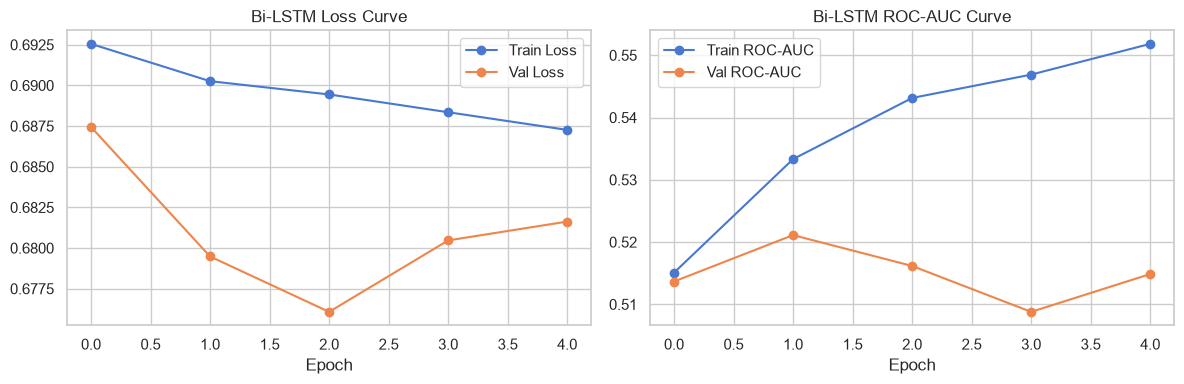

In [36]:
from sklearn.metrics import roc_auc_score, average_precision_score

# Predict readmission probabilities from the trained Bi-LSTM
dl_val_prob = bilstm_model.predict(X_seq_val, batch_size=256, verbose=0).ravel()
dl_test_prob = bilstm_model.predict(X_seq_test, batch_size=256, verbose=0).ravel()

print(f"Bi-LSTM Val  -> ROC-AUC: {roc_auc_score(y_val_dl, dl_val_prob):.4f} | PR-AUC: {average_precision_score(y_val_dl, dl_val_prob):.4f}")
print(f"Bi-LSTM Test -> ROC-AUC: {roc_auc_score(y_test, dl_test_prob):.4f} | PR-AUC: {average_precision_score(y_test, dl_test_prob):.4f}")

# Plot training vs validation curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['loss'], marker='o', label='Train Loss')
axes[0].plot(history.history['val_loss'], marker='o', label='Val Loss')
axes[0].set_title('Bi-LSTM Loss Curve')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history['roc_auc'], marker='o', label='Train ROC-AUC')
axes[1].plot(history.history['val_roc_auc'], marker='o', label='Val ROC-AUC')
axes[1].set_title('Bi-LSTM ROC-AUC Curve')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.show()

## Machine Learning Branch: Structured Readmission Modeling

In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

drop_cols = ['readmitted', 'patient_token', 'clinical_note']

X_train_raw = train_df.loc[tr_idx].drop(columns=drop_cols)
y_train_ml = train_df.loc[tr_idx, 'readmitted'].values

X_val_raw = train_df.loc[val_idx].drop(columns=drop_cols)
y_val_ml = train_df.loc[val_idx, 'readmitted'].values

X_test_raw = test_df.drop(columns=drop_cols)
y_test_ml = test_df['readmitted'].values

num_features = X_train_raw.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X_train_raw.select_dtypes(exclude=[np.number]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ]
)

X_train_ml = preprocessor.fit_transform(X_train_raw)
X_val_ml = preprocessor.transform(X_val_raw)
X_test_ml = preprocessor.transform(X_test_raw)

feature_names = preprocessor.get_feature_names_out()

print(f"Numerical: {len(num_features)} | Categorical: {len(cat_features)}")
print(f"Encoded shapes -> Train: {X_train_ml.shape} | Val: {X_val_ml.shape} | Test: {X_test_ml.shape}")

Numerical: 19 | Categorical: 20
Encoded shapes -> Train: (47579, 126) | Val: (8397, 126) | Test: (13994, 126)


In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

pos_weight = (y_train_ml == 0).sum() / (y_train_ml == 1).sum()

ml_models = {}
val_probs = {}
ml_results = {}

def evaluate_ml_model(name, model):
    model.fit(X_train_ml, y_train_ml)
    tr_prob = model.predict_proba(X_train_ml)[:, 1]
    va_prob = model.predict_proba(X_val_ml)[:, 1]

    ml_models[name] = model
    val_probs[name] = va_prob
    ml_results[name] = {
        'Model': name,
        'Train_ROC_AUC': round(roc_auc_score(y_train_ml, tr_prob), 4),
        'Val_ROC_AUC': round(roc_auc_score(y_val_ml, va_prob), 4),
        'Val_PR_AUC': round(average_precision_score(y_val_ml, va_prob), 4)
    }
    r = ml_results[name]
    print(f"{name} -> Train AUC: {r['Train_ROC_AUC']} | Val AUC: {r['Val_ROC_AUC']} | Val PR-AUC: {r['Val_PR_AUC']}")

In [39]:
lr_model = LogisticRegression(
    max_iter=1000, class_weight='balanced', random_state=SEED
)
evaluate_ml_model('Logistic Regression', lr_model)

Logistic Regression -> Train AUC: 0.6544 | Val AUC: 0.6446 | Val PR-AUC: 0.154


In [40]:
rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=12, min_samples_leaf=20,
    class_weight='balanced', n_jobs=-1, random_state=SEED
)
evaluate_ml_model('Random Forest', rf_model)

Random Forest -> Train AUC: 0.7842 | Val AUC: 0.6534 | Val PR-AUC: 0.156


In [41]:
xgb_model = XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pos_weight,
    tree_method='hist', eval_metric='logloss', n_jobs=-1, random_state=SEED
)
evaluate_ml_model('XGBoost', xgb_model)

XGBoost -> Train AUC: 0.7279 | Val AUC: 0.6462 | Val PR-AUC: 0.1514


In [42]:
lgbm_model = LGBMClassifier(
    n_estimators=200, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pos_weight,
    n_jobs=-1, random_state=SEED, verbose=-1
)
evaluate_ml_model('LightGBM', lgbm_model)

LightGBM -> Train AUC: 0.7663 | Val AUC: 0.6441 | Val PR-AUC: 0.153


In [43]:
ml_benchmark = pd.DataFrame(ml_results.values()).sort_values(
    by='Val_ROC_AUC', ascending=False
).reset_index(drop=True)
display(ml_benchmark)

,Model,Train_ROC_AUC,Val_ROC_AUC,Val_PR_AUC
0,Random Forest,0.7842,0.6534,0.1560
1,XGBoost,0.7279,0.6462,0.1514
2,Logistic Regression,0.6544,0.6446,0.1540
3,LightGBM,0.7663,0.6441,0.1530


In [44]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

xgb_param_grid = {
    'n_estimators': [150, 250, 350],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.02, 0.03, 0.05],
    'min_child_weight': [10, 25, 50],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.6, 0.7, 0.8],
    'reg_alpha': [0.5, 1.0, 5.0],
    'reg_lambda': [2.0, 5.0, 10.0]
}

xgb_base = XGBClassifier(
    scale_pos_weight=pos_weight,
    tree_method='hist',
    eval_metric='logloss',
    n_jobs=-1,
    random_state=SEED
)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

In [46]:
import gc
gc.collect()

xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=xgb_param_grid,
    n_iter=15,
    scoring='roc_auc',
    cv=cv,
    n_jobs=1,
    random_state=SEED,
    verbose=1
)

xgb_search.fit(X_train_ml.astype(np.float32), y_train_ml)
best_xgb = xgb_search.best_estimator_

print("Best CV ROC-AUC:", round(xgb_search.best_score_, 4))
print("Best Params:", xgb_search.best_params_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best CV ROC-AUC: 0.6494
Best Params: {'subsample': 0.8, 'reg_lambda': 10.0, 'reg_alpha': 0.5, 'n_estimators': 350, 'min_child_weight': 50, 'max_depth': 4, 'learning_rate': 0.02, 'colsample_bytree': 0.6}


In [47]:
evaluate_ml_model('XGBoost (Tuned)', best_xgb)

ml_benchmark = pd.DataFrame(ml_results.values()).sort_values(
    by='Val_ROC_AUC', ascending=False
).reset_index(drop=True)
display(ml_benchmark)

XGBoost (Tuned) -> Train AUC: 0.696 | Val AUC: 0.6551 | Val PR-AUC: 0.1578


,Model,Train_ROC_AUC,Val_ROC_AUC,Val_PR_AUC
0,XGBoost (Tuned),0.6960,0.6551,0.1578
1,Random Forest,0.7842,0.6534,0.1560
2,XGBoost,0.7279,0.6462,0.1514
3,Logistic Regression,0.6544,0.6446,0.1540
4,LightGBM,0.7663,0.6441,0.1530


## Hybrid Fusion, Threshold Tuning & Final Test Evaluation

In [48]:
ml_ens_val = (
    0.50 * val_probs['XGBoost (Tuned)']
    + 0.30 * val_probs['Random Forest']
    + 0.20 * val_probs['Logistic Regression']
)

print(
    f"ML Ensemble Val -> ROC-AUC: {roc_auc_score(y_val_ml, ml_ens_val):.4f} "
    f"| PR-AUC: {average_precision_score(y_val_ml, ml_ens_val):.4f}"
)

ML Ensemble Val -> ROC-AUC: 0.6556 | PR-AUC: 0.1594


In [49]:
fusion_candidates = {
    'XGBoost (Tuned) Only': val_probs['XGBoost (Tuned)'],
    'ML Ensemble (XGB + RF + LR)': ml_ens_val,
    'Hybrid (90% ML Ens + 10% Bi-LSTM)': 0.90 * ml_ens_val + 0.10 * dl_val_prob,
    'Hybrid (80% ML Ens + 20% Bi-LSTM)': 0.80 * ml_ens_val + 0.20 * dl_val_prob,
    'Hybrid (70% ML Ens + 30% Bi-LSTM)': 0.70 * ml_ens_val + 0.30 * dl_val_prob
}

In [50]:
fusion_rows = [
    {
        'Strategy': name,
        'Val_ROC_AUC': round(roc_auc_score(y_val_ml, prob), 4),
        'Val_PR_AUC': round(average_precision_score(y_val_ml, prob), 4)
    }
    for name, prob in fusion_candidates.items()
]

fusion_df = pd.DataFrame(fusion_rows).sort_values(
    by='Val_ROC_AUC', ascending=False
).reset_index(drop=True)
display(fusion_df)

,Strategy,Val_ROC_AUC,Val_PR_AUC
0,ML Ensemble (XGB + RF + LR),0.6556,0.1594
1,Hybrid (90% ML Ens + 10% Bi-LSTM),0.6552,0.1588
2,XGBoost (Tuned) Only,0.6551,0.1578
3,Hybrid (80% ML Ens + 20% Bi-LSTM),0.6546,0.1571
4,Hybrid (70% ML Ens + 30% Bi-LSTM),0.6536,0.1557


In [51]:
from sklearn.metrics import roc_curve, precision_recall_curve, f1_score, precision_score, recall_score

# Optimal F1 threshold
prec, rec, pr_thresh = precision_recall_curve(y_val_ml, ml_ens_val)
f1_scores = 2 * (prec[:-1] * rec[:-1]) / (prec[:-1] + rec[:-1] + 1e-8)
best_f1_thresh = pr_thresh[np.argmax(f1_scores)]

# Youden's J threshold (balances sensitivity and specificity)
fpr, tpr, roc_thresh = roc_curve(y_val_ml, ml_ens_val)
youden_thresh = roc_thresh[np.argmax(tpr - fpr)]

thresh_rows = []
for label, t in [('Default (0.50)', 0.50), ('Best F1', best_f1_thresh), ("Youden's J", youden_thresh)]:
    preds = (ml_ens_val >= t).astype(int)
    thresh_rows.append({
        'Method': label,
        'Threshold': round(float(t), 4),
        'Precision': round(precision_score(y_val_ml, preds), 4),
        'Recall': round(recall_score(y_val_ml, preds), 4),
        'F1': round(f1_score(y_val_ml, preds), 4)
    })

display(pd.DataFrame(thresh_rows))

,Method,Threshold,Precision,Recall,F1
0,Default (0.50),0.5000,0.1413,0.5631,0.2259
1,Best F1,0.5105,0.1472,0.5432,0.2317
2,Youden's J,0.4649,0.1329,0.6733,0.2219


In [52]:
xgb_test_prob = ml_models['XGBoost (Tuned)'].predict_proba(X_test_ml)[:, 1]
rf_test_prob = ml_models['Random Forest'].predict_proba(X_test_ml)[:, 1]
lr_test_prob = ml_models['Logistic Regression'].predict_proba(X_test_ml)[:, 1]

ml_ens_test = 0.50 * xgb_test_prob + 0.30 * rf_test_prob + 0.20 * lr_test_prob
hybrid_90_test = 0.90 * ml_ens_test + 0.10 * dl_test_prob

test_candidates = {
    'Bi-LSTM (Clinical Text Only)': dl_test_prob,
    'Logistic Regression': lr_test_prob,
    'Random Forest': rf_test_prob,
    'XGBoost (Tuned)': xgb_test_prob,
    'Hybrid (90% ML Ens + 10% Bi-LSTM)': hybrid_90_test,
    'ML Ensemble (XGB + RF + LR)': ml_ens_test
}

test_rows = [
    {
        'Model': name,
        'Test_ROC_AUC': round(roc_auc_score(y_test_ml, prob), 4),
        'Test_PR_AUC': round(average_precision_score(y_test_ml, prob), 4)
    }
    for name, prob in test_candidates.items()
]

test_summary = pd.DataFrame(test_rows).sort_values(
    by='Test_ROC_AUC', ascending=False
).reset_index(drop=True)
display(test_summary)

,Model,Test_ROC_AUC,Test_PR_AUC
0,XGBoost (Tuned),0.6454,0.1616
1,ML Ensemble (XGB + RF + LR),0.6451,0.1599
2,Hybrid (90% ML Ens + 10% Bi-LSTM),0.6450,0.1596
3,Random Forest,0.6420,0.1571
4,Logistic Regression,0.6349,0.1497
5,Bi-LSTM (Clinical Text Only),0.4933,0.0865


Final Test Classification Report (ML Ensemble @ threshold = 0.5105):

                 precision    recall  f1-score   support

   Low Risk (0)       0.94      0.70      0.80     12739
High Risk (<30)       0.14      0.52      0.23      1255

       accuracy                           0.68     13994
      macro avg       0.54      0.61      0.51     13994
   weighted avg       0.87      0.68      0.75     13994



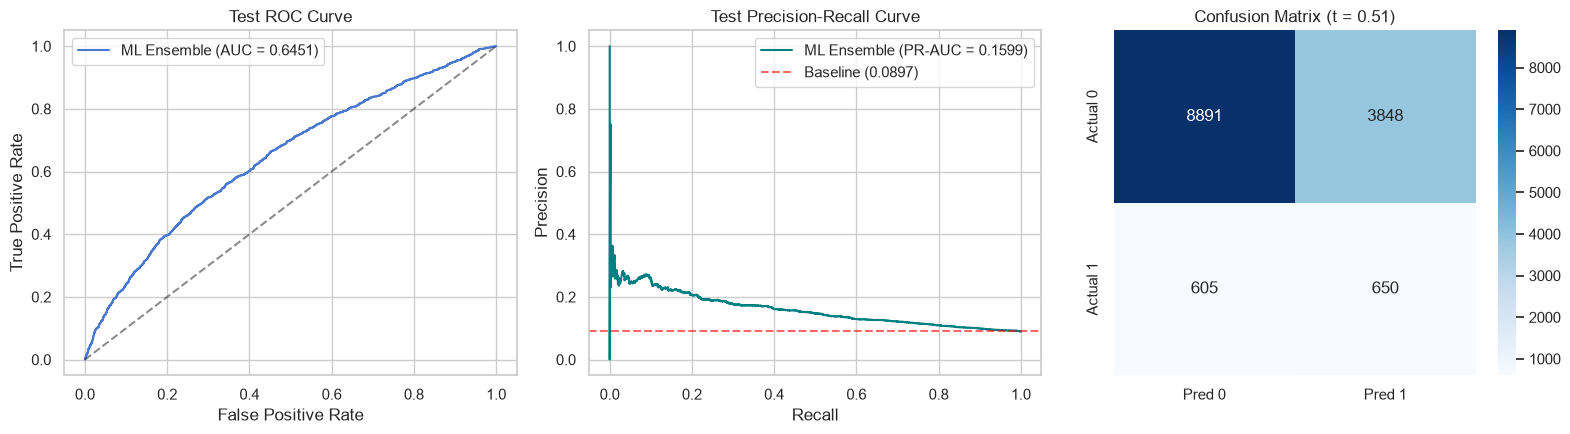

In [53]:
from sklearn.metrics import confusion_matrix, classification_report

chosen_thresh = float(best_f1_thresh)
y_test_pred = (ml_ens_test >= chosen_thresh).astype(int)

print(f"Final Test Classification Report (ML Ensemble @ threshold = {chosen_thresh:.4f}):\n")
print(classification_report(y_test_ml, y_test_pred, target_names=['Low Risk (0)', 'High Risk (<30)']))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# ROC Curve
fpr_t, tpr_t, _ = roc_curve(y_test_ml, ml_ens_test)
axes[0].plot(fpr_t, tpr_t, label=f"ML Ensemble (AUC = {roc_auc_score(y_test_ml, ml_ens_test):.4f})")
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title('Test ROC Curve')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend()

# Precision-Recall Curve
prec_t, rec_t, _ = precision_recall_curve(y_test_ml, ml_ens_test)
axes[1].plot(rec_t, prec_t, color='teal', label=f"ML Ensemble (PR-AUC = {average_precision_score(y_test_ml, ml_ens_test):.4f})")
axes[1].axhline(y_test_ml.mean(), color='red', linestyle='--', alpha=0.6, label=f"Baseline ({y_test_ml.mean():.4f})")
axes[1].set_title('Test Precision-Recall Curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()

# Confusion Matrix
cm = confusion_matrix(y_test_ml, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
            xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
axes[2].set_title(f'Confusion Matrix (t = {chosen_thresh:.2f})')

plt.tight_layout()
plt.show()

## Clinical Explainability (SHAP Global & Local Analysis)

In [55]:
import shap

# Clean feature names for readable plots
clean_names = [
    name.replace('num__', '').replace('cat__', '')
    for name in feature_names
]

# Compute SHAP values on a reproducible test sample
rng = np.random.default_rng(SEED)
sample_pos = rng.choice(len(X_test_ml), size=1000, replace=False)
X_shap = pd.DataFrame(X_test_ml[sample_pos], columns=clean_names)

explainer = shap.TreeExplainer(ml_models['XGBoost (Tuned)'])
shap_values = explainer(X_shap)

print("SHAP values computed with shape:", shap_values.values.shape)

SHAP values computed with shape: (1000, 126)


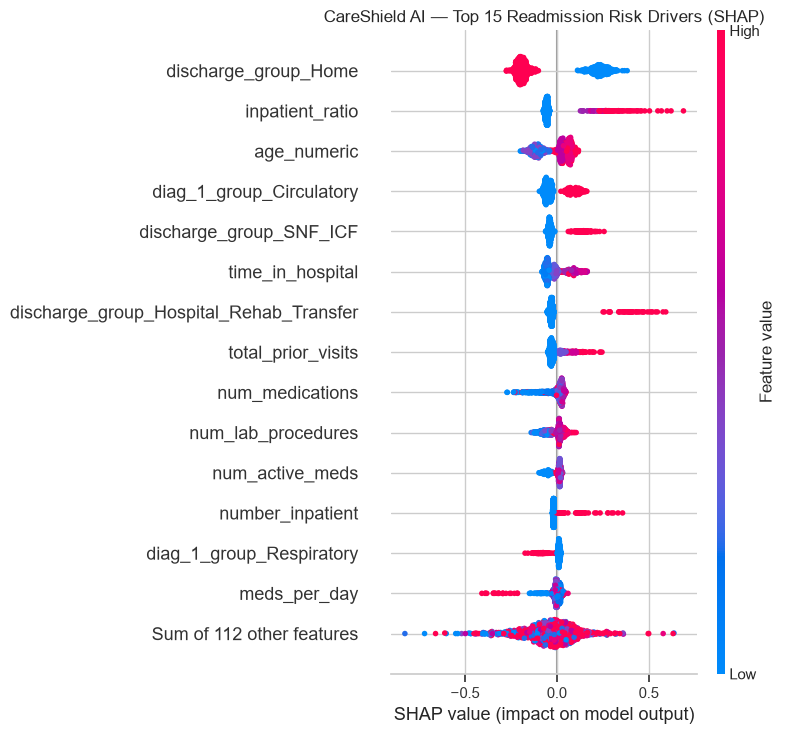

In [56]:
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title('CareShield AI — Top 15 Readmission Risk Drivers (SHAP)')
plt.tight_layout()
plt.show()

Selected Test Patient -> Ensemble Risk Score: 0.7743 | Actual Label: 0


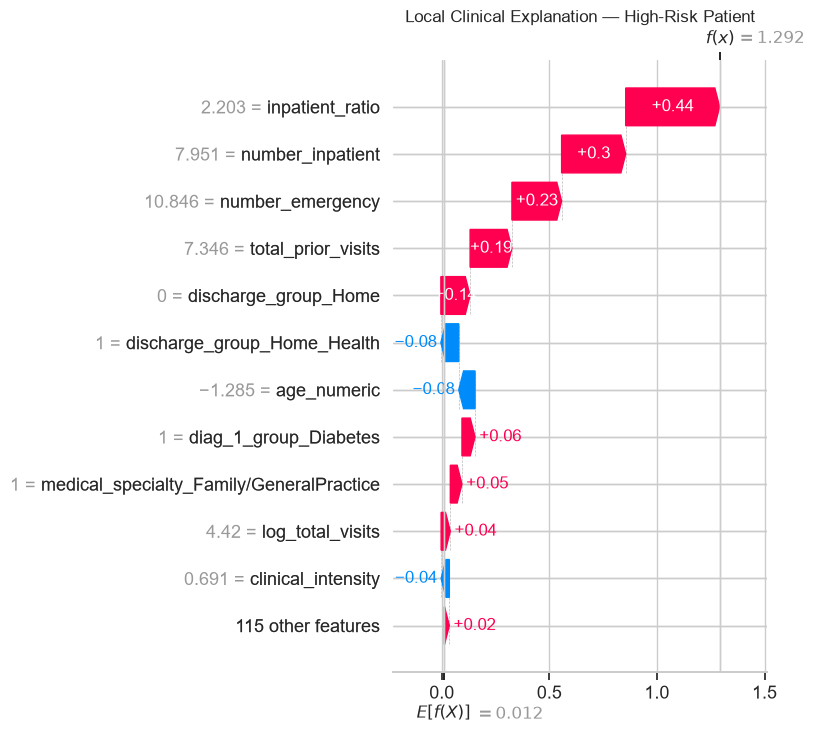

In [57]:
# Pick the highest-risk patient in the SHAP test sample
sample_probs = ml_ens_test[sample_pos]
top_risk_i = int(np.argmax(sample_probs))

print(
    f"Selected Test Patient -> Ensemble Risk Score: {sample_probs[top_risk_i]:.4f} "
    f"| Actual Label: {y_test_ml[sample_pos[top_risk_i]]}"
)

plt.figure(figsize=(9, 5))
shap.plots.waterfall(shap_values[top_risk_i], max_display=12, show=False)
plt.title('Local Clinical Explanation — High-Risk Patient')
plt.tight_layout()
plt.show()

## Export Production Artifacts & Inference Pipeline

In [58]:
import os
import json
import joblib

ARTIFACT_DIR = 'careshield_artifacts'
os.makedirs(ARTIFACT_DIR, exist_ok=True)

joblib.dump(preprocessor, f'{ARTIFACT_DIR}/preprocessor.joblib')
joblib.dump(ml_models['XGBoost (Tuned)'], f'{ARTIFACT_DIR}/xgb_tuned.joblib')
joblib.dump(ml_models['Random Forest'], f'{ARTIFACT_DIR}/rf_model.joblib')
joblib.dump(ml_models['Logistic Regression'], f'{ARTIFACT_DIR}/lr_model.joblib')
bilstm_model.save(f'{ARTIFACT_DIR}/bilstm_model.keras')

config = {
    'project': 'CareShield AI',
    'ensemble_weights': {'xgb': 0.50, 'rf': 0.30, 'lr': 0.20},
    'decision_threshold': round(float(chosen_thresh), 4),
    'test_roc_auc': round(float(roc_auc_score(y_test_ml, ml_ens_test)), 4),
    'test_pr_auc': round(float(average_precision_score(y_test_ml, ml_ens_test)), 4),
    'feature_columns': X_train_raw.columns.tolist()
}

with open(f'{ARTIFACT_DIR}/config.json', 'w') as f:
    json.dump(config, f, indent=2)

print("Saved artifacts:", os.listdir(ARTIFACT_DIR))

Saved artifacts: ['bilstm_model.keras', 'config.json', 'lr_model.joblib', 'preprocessor.joblib', 'rf_model.joblib', 'xgb_tuned.joblib']


In [59]:
loaded_prep = joblib.load(f'{ARTIFACT_DIR}/preprocessor.joblib')
loaded_xgb = joblib.load(f'{ARTIFACT_DIR}/xgb_tuned.joblib')
loaded_rf = joblib.load(f'{ARTIFACT_DIR}/rf_model.joblib')
loaded_lr = joblib.load(f'{ARTIFACT_DIR}/lr_model.joblib')

with open(f'{ARTIFACT_DIR}/config.json') as f:
    loaded_cfg = json.load(f)

loaded_explainer = shap.TreeExplainer(loaded_xgb)
loaded_feat_names = [
    c.replace('num__', '').replace('cat__', '')
    for c in loaded_prep.get_feature_names_out()
]

def predict_patient_risk(patient_df):
    X_enc = loaded_prep.transform(patient_df[loaded_cfg['feature_columns']])
    w = loaded_cfg['ensemble_weights']

    risk_prob = float(
        w['xgb'] * loaded_xgb.predict_proba(X_enc)[0, 1]
        + w['rf'] * loaded_rf.predict_proba(X_enc)[0, 1]
        + w['lr'] * loaded_lr.predict_proba(X_enc)[0, 1]
    )

    shap_vals = loaded_explainer.shap_values(X_enc)[0]
    top_idx = np.argsort(np.abs(shap_vals))[::-1][:3]
    top_drivers = [
        {'feature': loaded_feat_names[i], 'shap_impact': round(float(shap_vals[i]), 4)}
        for i in top_idx
    ]

    tier = 'High Risk' if risk_prob >= loaded_cfg['decision_threshold'] else 'Low Risk'
    return {
        'readmission_risk_score': round(risk_prob, 4),
        'risk_tier': tier,
        'threshold': loaded_cfg['decision_threshold'],
        'top_risk_drivers': top_drivers
    }

print("Inference pipeline loaded and ready.")

Inference pipeline loaded and ready.


In [60]:
pos_positions = np.where(y_test_ml == 1)[0]
high_risk_pos = pos_positions[np.argmax(ml_ens_test[pos_positions])]
low_risk_pos = int(np.argmin(ml_ens_test))

for label, pos in [('High-Risk Case', high_risk_pos), ('Low-Risk Case', low_risk_pos)]:
    sample_row = X_test_raw.iloc[[pos]]
    result = predict_patient_risk(sample_row)
    print(f"=== {label} (Actual: {y_test_ml[pos]}) ===")
    print(json.dumps(result, indent=2))

=== High-Risk Case (Actual: 1) ===
{
  "readmission_risk_score": 0.8426,
  "risk_tier": "High Risk",
  "threshold": 0.5105,
  "top_risk_drivers": [
    {
      "feature": "inpatient_ratio",
      "shap_impact": 0.5185
    },
    {
      "feature": "diag_2_group_Neoplasms",
      "shap_impact": 0.2661
    },
    {
      "feature": "number_inpatient",
      "shap_impact": 0.2625
    }
  ]
}
=== Low-Risk Case (Actual: 0) ===
{
  "readmission_risk_score": 0.1995,
  "risk_tier": "Low Risk",
  "threshold": 0.5105,
  "top_risk_drivers": [
    {
      "feature": "meds_per_day",
      "shap_impact": -0.2917
    },
    {
      "feature": "discharge_group_Home",
      "shap_impact": -0.2555
    },
    {
      "feature": "number_diagnoses",
      "shap_impact": -0.1667
    }
  ]
}


In [61]:
train_part = train_df.copy()
train_part['split'] = 'train'
train_part.loc[val_idx, 'split'] = 'val'

test_part = test_df.copy()
test_part['split'] = 'test'

final_secure_data = pd.concat([train_part, test_part], ignore_index=True)
final_secure_data.to_csv(f'{ARTIFACT_DIR}/final_secure_data.csv', index=False)
test_df.head(50).to_csv(f'{ARTIFACT_DIR}/sample_patients.csv', index=False)

print("Saved final_secure_data.csv -> shape:", final_secure_data.shape)
print(final_secure_data['split'].value_counts())

Saved final_secure_data.csv -> shape: (69970, 43)
split
train    47579
test     13994
val       8397
Name: count, dtype: int64


In [62]:
import os
import pandas as pd

os.makedirs('sql', exist_ok=True)
df_sec = pd.read_csv('careshield_artifacts/final_secure_data.csv')
print(df_sec.columns.tolist())

['race', 'gender', 'time_in_hospital', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'insulin', 'change', 'diabetesMed', 'readmitted', 'age_numeric', 'diag_1_group', 'diag_2_group', 'diag_3_group', 'num_active_meds', 'num_med_changes', 'discharge_group', 'admission_type_group', 'admission_source_group', 'total_prior_visits', 'log_total_visits', 'inpatient_ratio', 'meds_per_day', 'labs_per_day', 'clinical_intensity', 'has_prior_inpatient', 'has_prior_emergency', 'patient_token', 'clinical_note', 'split']
